In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

uploaded = files.upload()

Saving cleaned_dataset_day4.csv to cleaned_dataset_day4.csv


In [2]:
df = pd.read_csv("cleaned_dataset_day4.csv", parse_dates=["Date"])
df.head()

,Order_ID,Date,Customer,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,104,2026-10-04,Arun,Bengaluru,UPI_Device,Hardware,4,5000,20000
1,106,2026-10-06,Kiran,Hyderabad,POS_Machine,Hardware,2,8000,16000
2,109,2026-10-09,Anu,Mumbai,UPI_Device,Hardware,3,5000,15000
3,101,2026-10-01,Ravi,Bengaluru,UPI_Device,Hardware,2,5000,10000
4,103,2026-10-03,Priya,Chennai,POS_Machine,Hardware,1,8000,8000


In [3]:
sales = df["Total_Sales"]

print("Mean:", sales.mean())
print("Median:", sales.median())
print("Mode:", list(sales.mode()))

print("Quantity mean:", df["Quantity"].mean())
print("Quantity median:", df["Quantity"].median())
print("Quantity mode:", list(df["Quantity"].mode()))

Mean: 9800.0
Median: 8000.0
Mode: [6000, 8000]
Quantity mean: 3.2
Quantity median: 3.0
Quantity mode: [2]


In [4]:
print("Std (sample):", round(sales.std(), 2))
print("Std (population):", round(sales.std(ddof=0), 2))
print("Variance:", round(sales.var(), 2))
print("Range:", sales.max() - sales.min())

Std (sample): 5391.35
Std (population): 5114.68
Variance: 29066666.67
Range: 16000


In [5]:
corr = df[["Quantity", "Unit_Price", "Total_Sales"]].corr()
print(corr.round(2))

             Quantity  Unit_Price  Total_Sales
Quantity         1.00       -0.72        -0.13
Unit_Price      -0.72        1.00         0.63
Total_Sales     -0.13        0.63         1.00


In [6]:
total = len(df)

# P(Hardware order)
p_hw = (df["Category"] == "Hardware").sum() / total
print("P(Hardware):", p_hw)

# P(sale > 10000)
p_high = (df["Total_Sales"] > 10000).sum() / total
print("P(Sale > 10000):", p_high)

# P(Bengaluru)
p_blr = (df["City"] == "Bengaluru").sum() / total
print("P(Bengaluru):", p_blr)

# Conditional: P(sale > 10000 | Hardware)
hw = df[df["Category"] == "Hardware"]
print("P(Sale > 10000 | Hardware):", (hw["Total_Sales"] > 10000).sum() / len(hw))

P(Hardware): 0.5
P(Sale > 10000): 0.3
P(Bengaluru): 0.3
P(Sale > 10000 | Hardware): 0.6


Slope: 1.26
Intercept: 4884.44
R-squared: 0.394
Predicted sales for price 6000: 12446.84


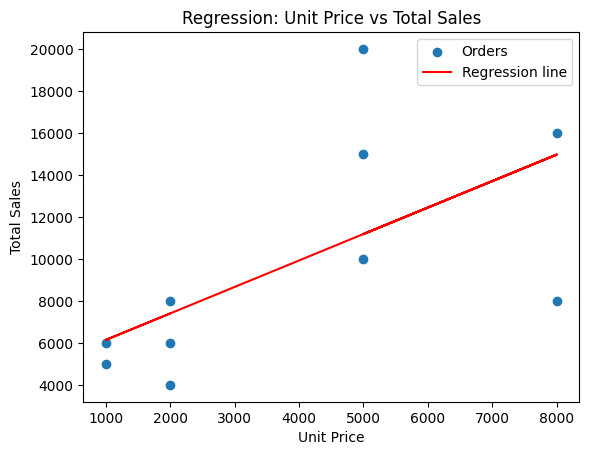

In [7]:
result = stats.linregress(df["Unit_Price"], df["Total_Sales"])

print("Slope:", round(result.slope, 3))
print("Intercept:", round(result.intercept, 2))
print("R-squared:", round(result.rvalue ** 2, 3))

# prediction
price = 6000
predicted = result.intercept + result.slope * price
print("Predicted sales for price 6000:", round(predicted, 2))

# chart
plt.scatter(df["Unit_Price"], df["Total_Sales"], label="Orders")
plt.plot(df["Unit_Price"], result.intercept + result.slope * df["Unit_Price"], color="red", label="Regression line")
plt.xlabel("Unit Price")
plt.ylabel("Total Sales")
plt.title("Regression: Unit Price vs Total Sales")
plt.legend()
plt.show()

Summary
- Average sale is 9,800 but the median is 8,000, so a few big orders pull the average up.
- Standard deviation is 5,391, so sales vary a lot between orders.
- Unit price and total sales are moderately correlated (0.63).
- 30% of orders are above 10,000, and all of them are Hardware.
- Simple regression: Total_Sales = 4884 + 1.26 x Unit_Price (R2 = 0.39). Dataset is small, so results are indicative.
